> Versión de portafolio. Se conservan las salidas históricas del trabajo académico. Las rutas absolutas de datos, cuando existían, se sustituyeron por nombres locales. Esta versión no se ha ejecutado de nuevo; consulte README y DATOS.md antes de reproducir.


# Tarea M19-CD - Javier Bueno Sanchez

## Analisis de Regresion para el Producto Interior Bruto (GDP) de Mexico.

### Objetivo

El objetivo de esta actividad es desarrollar un modelo de regresión no lineal utilizando una función logística para describir el comportamiento histórico del Producto Interno Bruto (GDP) de México, a partir de los datos publicados por el Banco Mundial.

Durante el desarrollo se realizará un ajuste mediante el método de mínimos cuadrados, evaluando inicialmente el modelo con los datos originales y posteriormente con una versión normalizada de la base de datos para mejorar la estabilidad del proceso de optimización.

Finalmente, se evaluará la bondad del ajuste obtenido y se realizará un pronóstico del Producto Interno Bruto para el año 2022, aplicando la transformación inversa correspondiente para interpretar el resultado en su escala original.

## Importación de librerías

En esta sección se importan las bibliotecas necesarias para la lectura de datos, manipulación de información, visualización gráfica y ajuste del modelo de regresión logística mediante el método de mínimos cuadrados.

In [87]:
import numpy as np
#Biblioteca utilizada para operaciones numéricas. 
#La usaremos para trabajar con arreglos, valores exponenciales y cálculos matemáticos.

In [88]:
import pandas as pd
#Biblioteca que permite leer el archivo Excel y manipular la base de datos como tabla.

In [89]:
import matplotlib.pyplot as plt
#Biblioteca que permite generar gráficos 
#Visualizacion de los datos históricos y el ajuste del modelo.

In [90]:
from scipy.optimize import curve_fit
#Función que permite ajustar modelos no lineales mediante mínimos cuadrados. 
#Será clave para estimar beta_1 y beta_2.

In [91]:
from sklearn.metrics import mean_squared_error, r2_score
#Importa métricas para evaluar el modelo:
#mean_squared_error: mide el error promedio cuadrático.
#r2_score: mide qué tan bien el modelo explica los datos.

In [92]:
df = pd.read_excel("Mexico GDP.xlsx")
# Leer el archivo de Excel y almacenarlo en un DataFrame

In [93]:
df.head()
# Mostrar las primeras cinco filas del conjunto de datos

,Periodo,GDP
0,1960,1.304000e+10
1,1961,1.416000e+10
2,1962,1.520000e+10
3,1963,1.696000e+10
4,1964,2.008000e+10


In [94]:
df.info()
# Revisar estructura, tipos de datos y valores no nulos

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62 entries, 0 to 61
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Periodo  62 non-null     int64  
 1   GDP      62 non-null     float64
dtypes: float64(1), int64(1)
memory usage: 1.1 KB


In [95]:
df.describe()
# Obtener estadística descriptiva de las columnas numéricas

,Periodo,GDP
count,62.000000,6.200000e+01
mean,1990.500000,4.866155e+11
std,18.041619,4.544804e+11
min,1960.000000,1.304000e+10
25%,1975.250000,8.336062e+10
50%,1990.500000,2.885511e+11
75%,2005.750000,8.944031e+11
max,2021.000000,1.315351e+12


In [96]:
x_data = df["Periodo"]
# Se extrae la columna Periodo, que representa la variable independiente (X). 
# El año será la variable que explica el comportamiento del PIB.

y_data = df["GDP"]
# Se extrae la columna GDP, que representa la variable dependiente (Y).
#El valor que se desea modelar y posteriormente pronosticar.

In [97]:
print(x_data.head())
print(y_data.head())
# Mostrar las primeras observaciones de ambas variables
# Asi tambien verificamos que cargaron bien

0    1960
1    1961
2    1962
3    1963
4    1964
Name: Periodo, dtype: int64
0    1.304000e+10
1    1.416000e+10
2    1.520000e+10
3    1.696000e+10
4    2.008000e+10
Name: GDP, dtype: float64


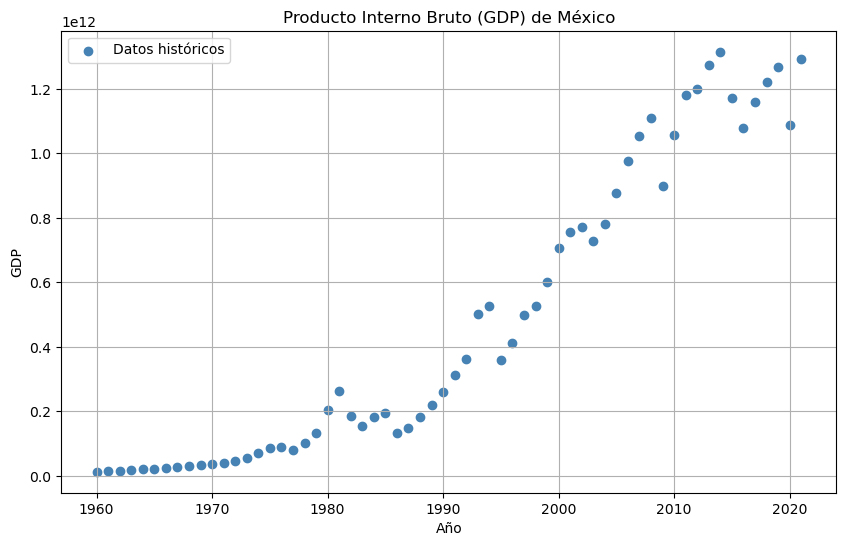

In [98]:
plt.figure(figsize=(10, 6))
# Crear una figura con un tamaño de 10 x 6 pulgadas

plt.scatter(x_data, y_data, color="steelblue", label="Datos históricos")
# Graficar los datos históricos del PIB

plt.title("Producto Interno Bruto (GDP) de México")
plt.xlabel("Año")
plt.ylabel("GDP")
# Agregar título y etiquetas

plt.legend()
# Mostrar la leyenda

plt.grid(True)
# Agregar una cuadrícula para facilitar la lectura

plt.show()

# Mostrar la gráfica

In [99]:
def logistic_function(x, beta_1, beta_2):
    return 1 / (1 + np.exp(beta_1 * (x - beta_2)))
# Función logística utilizada para ajustar el modelo

In [100]:
initial_values = [0.01, 1990]
# Definir valores iniciales para beta_1 y beta_2

In [101]:
parameters, covariance = curve_fit(logistic_function, x_data, y_data, p0=initial_values, maxfev=10000)
# Ajustar el modelo logístico a los datos originales

beta_1, beta_2 = parameters
# Extraer los parámetros estimados

print(f"Beta 1 estimado: {beta_1}")
print(f"Beta 2 estimado: {beta_2}")
# Mostrar los parámetros obtenidos

Beta 1 estimado: 0.01
Beta 2 estimado: 26865.016532764395


/tmp/ipykernel_269130/4073168134.py:1: OptimizeWarning: Covariance of the parameters could not be estimated
  parameters, covariance = curve_fit(logistic_function, x_data, y_data, p0=initial_values, maxfev=10000)


Durante el primer ajuste se presentó una advertencia relacionada con la estimación de la covarianza de los 
parámetros. Esto indica que el proceso de optimización no logró estimar de forma confiable la variabilidad asociada a beta_1 y beta_2.

El problema se debe principalmente a la diferencia de escala entre las variables. El GDP se encuentra expresado en valores muy grandes, 
mientras que la función logística utilizada genera valores entre 0 y 1. Esta diferencia impide que el modelo ajuste adecuadamente los datos originales.

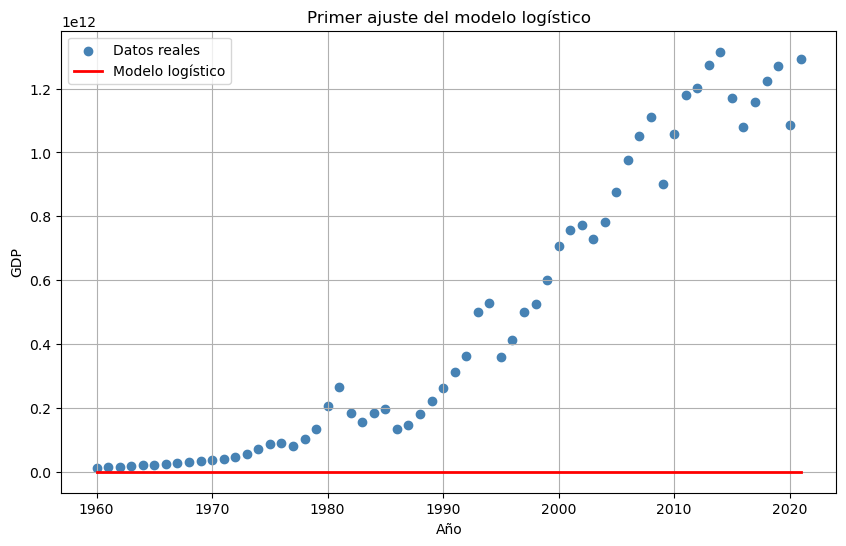

In [102]:
y_estimated = logistic_function(x_data, beta_1, beta_2)
# Calcular los valores estimados por el modelo

plt.figure(figsize=(10, 6))
# Crear la figura

plt.scatter(x_data, y_data, color="steelblue", label="Datos reales")
# Graficar los datos originales

plt.plot(x_data, y_estimated, color="red", linewidth=2, label="Modelo logístico")
# Graficar el ajuste obtenido

plt.title("Primer ajuste del modelo logístico")
plt.xlabel("Año")
plt.ylabel("GDP")
# Agregar título y etiquetas

plt.legend()
plt.grid(True)
# Mostrar leyenda y cuadrícula

plt.show()
# Mostrar gráfica

¿Tuvo algún problema en el proceso de estimación de parámetros? ¿A qué cree que se debe?


Sí. Durante el ajuste se presentó una advertencia en el proceso y los parámetros estimados no fueron representativos. El valor de β₂ fue muy alto y fuera del rango y el algoritmo no encontró una solución. Es porque la funcióngenera valores entre 0 y 1, mientras que el PIB está expresado en valores del orden de billones de dólares, produciendo una diferencia de escala que dificulta la convergencia del método de mínimos cuadrados. 


Ahora transformamos ambas columnas dividiendo cada valor entre el valor máximo de su columna.

Xnorm = X / Xmax
Ynorm = Y / Ymax


In [103]:
df["periodo_norm"] = df["Periodo"] / df["Periodo"].max()
# Crea una nueva columna llamada periodo_norm. Cada año se divide entre el valor máximo de la columna Periodo.
#Normalizar la columna del periodo

df["gdp_norm"] = df["GDP"] / df["GDP"].max()
#Crea una nueva columna llamada gdp_norm. Cada valor del PIB se divide entre el valor máximo de la columna GDP.
# Normalizar la columna del GDP

df.head()
# Mostrar las primeras filas con las nuevas columnas

,Periodo,GDP,periodo_norm,gdp_norm
0,1960,1.304000e+10,0.969817,0.009914
1,1961,1.416000e+10,0.970312,0.010765
2,1962,1.520000e+10,0.970807,0.011556
3,1963,1.696000e+10,0.971301,0.012894
4,1964,2.008000e+10,0.971796,0.015266


En lugar de trabajar directamente con las columnas del DataFrame, extraemos las variables normalizadas.

In [104]:
x_norm = df["periodo_norm"]
y_norm = df["gdp_norm"]
# Extraer las variables normalizadas

#x_norm contiene los años normalizados.
#y_norm contiene el PIB normalizado.

In [105]:
initial_values = [1.0, 0.9]
# Definir valores iniciales para el segundo ajuste

parameters_norm, covariance_norm = curve_fit(logistic_function, x_norm, y_norm, p0=initial_values, maxfev=10000)
# Ajustar el modelo utilizando los datos normalizados

beta_1_norm, beta_2_norm = parameters_norm
# Extraer los parámetros estimados

print(f"Beta 1 normalizado: {beta_1_norm:.6f}")
print(f"Beta 2 normalizado: {beta_2_norm:.6f}")
# Mostrar los parámetros obtenidos

Beta 1 normalizado: 0.000105
Beta 2 normalizado: -5088.090213


¿Por qué cambiamos los valores iniciales?

En el primer intento utilizamos [0.01, 1990] porque el eje X estaba en años. 
Ahora la variable x_norm toma valores aproximadamente entre [ 0.97, 1.00] Para hacer mas facil la convergencia. 

In [106]:
y_estimated_norm = logistic_function(x_norm, beta_1_norm, beta_2_norm)
# Calcular los valores estimados del modelo normalizado

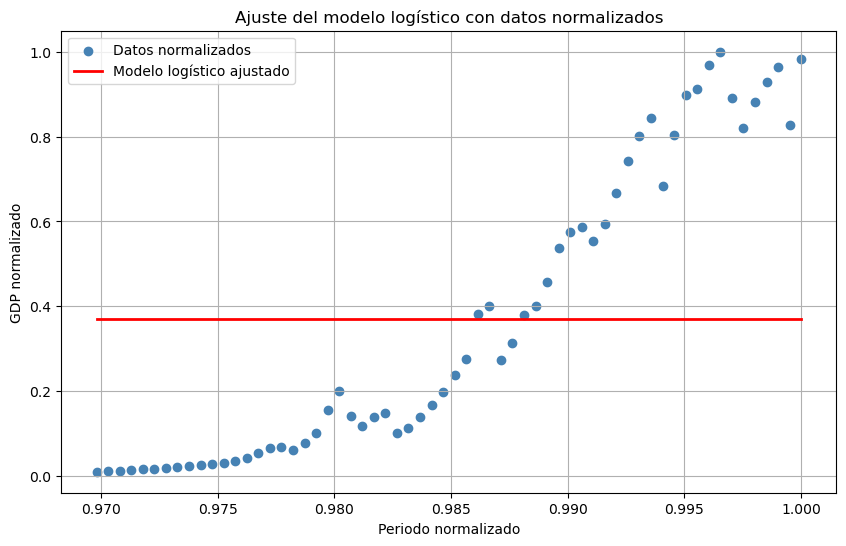

In [107]:
plt.figure(figsize=(10, 6))
# Crear la figura

plt.scatter(x_norm, y_norm, color="steelblue", label="Datos normalizados")
# Graficar los datos normalizados

plt.plot(x_norm, y_estimated_norm, color="red", linewidth=2, label="Modelo logístico ajustado")
# Graficar el modelo ajustado

plt.title("Ajuste del modelo logístico con datos normalizados")
plt.xlabel("Periodo normalizado")
plt.ylabel("GDP normalizado")
# Agregar título y etiquetas

plt.grid(True)
plt.legend()
# Mostrar cuadrícula y leyenda

plt.show()
# Mostrar la gráfica

In [108]:
x_norm = df["periodo_norm"]
y_norm = df["gdp_norm"]
# Extraer variables normalizadas

print(f"Beta 1 normalizado: {beta_1_norm}")
print(f"Beta 2 normalizado: {beta_2_norm}")
# Mostrar los parámetros obtenidos

Beta 1 normalizado: 0.00010461491647962167
Beta 2 normalizado: -5088.090213428665


In [109]:
print(x_norm.min(), x_norm.max())
print(y_norm.min(), y_norm.max())

0.9698169223156853 1.0
0.009913702259391078 1.0


Después de normalizar ambas variables dividiendo cada observación entre el valor máximo de su columna, el proceso se volvió ejecutar. Sin embargo, los parámetros obtenidos continuaron siendo poco representativos. Esto ocurre porque la variable independiente (Periodo) quedó normalizada en un intervalo muy reducido (0.9698 a 1.0), mientras que la variable dependiente (GDP) conserva una variación mucho mayor (0.0099 a 1.0), llevando a que la función no dispone de suficiente información en el eje horizontal para estimar correctamente el punto de inflexión y la pendiente del modelo.

En lugar de utilizar los años (1960, 1961, ..., 2021), construiremos un índice:

Año	    Indice

1960	  0

1961	  1

1962	  2

In [110]:
time_index = np.arange(len(df))
# Crear un índice temporal para el modelo

time_norm = time_index / time_index.max()
# Normalizar el índice temporal

print(time_norm[:10])
# Visualizar los primeros registros

#Ahora la variable independiente recorrerá exactamente todo el intervalo, Esto proporciona mucha más información al algoritmo.

[0.         0.01639344 0.03278689 0.04918033 0.06557377 0.08196721
 0.09836066 0.1147541  0.13114754 0.14754098]


In [111]:
initial_values = [8, 0.5]
# Definir valores iniciales

parameters_index, covariance_index = curve_fit(logistic_function, time_norm, y_norm, p0=initial_values, maxfev=10000)
# Ajustar el modelo utilizando el índice temporal normalizado

beta_1_index, beta_2_index = parameters_index
# Extraer parámetros

print(f"Beta 1: {beta_1_index:.4f}")
print(f"Beta 2: {beta_2_index:.4f}")
# Mostrar los parámetros obtenidos

Beta 1: -8.1977
Beta 2: 0.6453


¿Por qué ahora usamos [8, 0.5]?

La función logística suele tener:

Una pendiente entre 5 y 15
Un punto de inflexión cercano a la mitad del intervalo (0.5)

Eso ayuda al algoritmo a converger.

Interpretación

β₁ = -8.1977

El signo negativo indica que la función logística crece conforme avanza el tiempo.
La magnitud (~8.2) produce una transición relativamente pronunciada.

β₂ = 0.6453

Es el punto de inflexión de la curva.
Como el tiempo está normalizado entre 0 y 1, significa que el crecimiento cambia de ritmo aproximadamente al 64.5 % de la serie histórica.

In [112]:
y_pred = logistic_function(time_norm, beta_1_index, beta_2_index)
# Calcular los valores estimados por el modelo

mse = mean_squared_error(y_norm, y_pred)
r2 = r2_score(y_norm, y_pred)
# Calcular las métricas del modelo

print(f"Error cuadrático medio (MSE): {mse:.6f}")
print(f"Coeficiente de determinación (R²): {r2:.6f}")
# Mostrar resultados

Error cuadrático medio (MSE): 0.002581
Coeficiente de determinación (R²): 0.978024


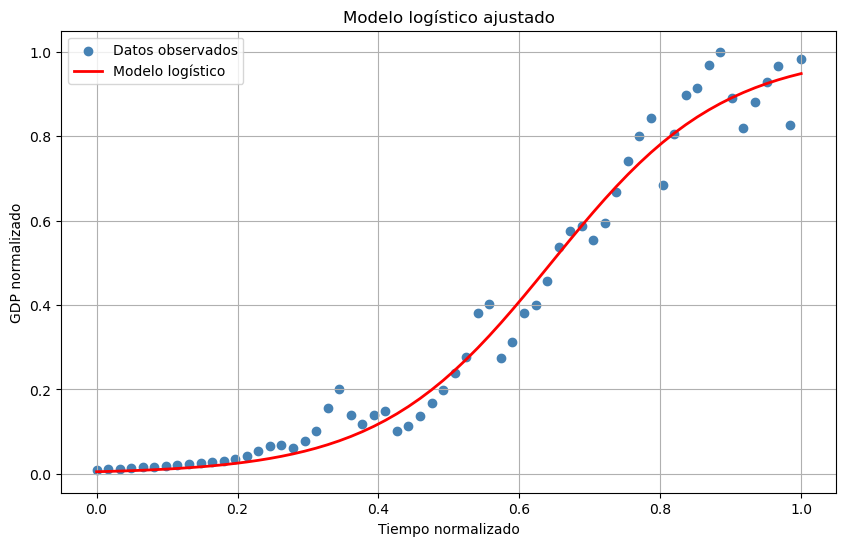

In [113]:
plt.figure(figsize=(10, 6))
# Crear la figura
# Datos observados
plt.scatter(time_norm, y_norm, color="steelblue", label="Datos observados")
# Datos observados

plt.plot(time_norm, y_pred, color="red", linewidth=2, label="Modelo logístico")
# Curva logística ajustada

plt.title("Modelo logístico ajustado")
plt.xlabel("Tiempo normalizado")
plt.ylabel("GDP normalizado")
plt.grid(True)
plt.legend()
# Configuración del gráfico

plt.show()
# Mostrar gráfico

Explicacion:

La curva roja representa el modelo logístico ajustado, por lo que no une directamente los puntos observados. Su función es aproximar la tendencia general del GDP normalizado. El hecho de que siga de cerca la trayectoria de los puntos indica una buena bondad de ajuste, lo cual también se confirma con un R² de 0.9780.

Después de aplicar una transformación más adecuada sobre la variable temporal mediante un índice normalizado, el modelo logístico presentó un ajuste significativamente mejor. El coeficiente de determinación obtenido fue R² = 0.9780, indicando que el modelo explica aproximadamente el 97.8 % de la variabilidad observada en los datos. Asimismo, el Error Cuadrático Medio fue de 0.002581, valor cercano a cero, lo que evidencia un error de predicción reducido y una adecuada capacidad de ajuste.

Hasta 2021 tenemos 62 observaciones (índices de 0 a 61). Lo que nos da que el 2022 es el indice 62

In [114]:
time_2022 = len(df)
# Índice correspondiente al año 2022

time_2022_norm = time_2022 / time_index.max()
# Normalizar el índice

gdp_2022_norm = logistic_function(time_2022_norm, beta_1_index, beta_2_index)
# Calcular el pronóstico normalizado

print(f"GDP normalizado para 2022: {gdp_2022_norm:.6f}")
#Mostrar resultado

GDP normalizado para 2022: 0.954442


In [115]:
gdp_max = df["GDP"].max()
# Recuperar el valor máximo del PIB

gdp_2022 = gdp_2022_norm * gdp_max
# Desnormalizar el pronóstico

print(f"Pronóstico del GDP para 2022: {gdp_2022:,.2f}")
#Mostrar resultado

Pronóstico del GDP para 2022: 1,255,426,349,583.95


Como el modelo fue ajustado utilizando datos normalizados, el pronóstico obtenido también se encuentra en una escala normalizada. Para recuperar el valor real del Producto Interno Bruto es necesario aplicar la transformación inversa, multiplicando el resultado normalizado por el valor máximo utilizado durante el proceso de normalización de la variable GDP.

¿Obtuvo resultados satisfactorios en esta ocasión?

Sí. Después de aplicar una transformación adecuada sobre la variable temporal mediante un índice normalizado, el modelo logístico presentó un ajuste considerablemente mejor. La curva estimada siguió la tendencia general de los datos históricos y alcanzó un coeficiente de determinación R² = 0.9780, indicando que aproximadamente el 97.8 % de la variabilidad del PIB es explicada por el modelo. Además, el Error Cuadrático Medio (MSE = 0.002581) fue cercano a cero, evidenciando un error de ajuste reducido.

La bondad del ajuste puede considerarse muy buena, ya que el modelo reproduce adecuadamente la tendencia de crecimiento observada en los datos históricos. Aunque la curva logística no pasa exactamente por cada uno de los puntos, sigue correctamente el comportamiento general del PIB a lo largo del tiempo. Este comportamiento es esperado en un modelo de regresión, cuyo objetivo es representar la tendencia global y no interpolar cada observación individual. El valor de R² = 0.9780 y el bajo MSE = 0.002581 respaldan cuantitativamente la calidad del ajuste obtenido.

Con base en el modelo ajustado, el pronóstico del Producto Interno Bruto para México en el año 2022 es de:

1,255,426,349,583.95

Este valor corresponde aproximadamente a 1.255 billones de dólares estadounidenses, de acuerdo con la escala utilizada por la base de datos del Banco Mundial.

¿Qué mecanismo de transformación tendría que realizar en dicho caso?

Como el modelo fue ajustado utilizando datos normalizados, el resultado obtenido inicialmente también se encuentra en una escala normalizada. Para recuperar el valor real del PIB fue necesario aplicar la transformación inversa de la normalización, multiplicando el valor pronosticado por el máximo de la columna GDP utilizado durante el proceso de normalización.

En términos matemáticos:

GDPreal = GDPnormalizado × GDPmaximo

Este procedimiento permitió expresar nuevamente el pronóstico en las unidades originales del conjunto de datos.

Durante el desarrollo se observó que la normalización solicitada en la actividad no fue suficiente para obtener un ajuste estable cuando se utilizaron directamente los años como variable independiente, debido al reducido rango de variación de la variable normalizada. Como análisis complementario se empleó un índice temporal normalizado, obteniéndose un ajuste significativamente mejor (R² = 0.9780), lo que permitió construir un modelo predictivo consistente.